<a href="https://colab.research.google.com/github/balavardhansai/ML/blob/main/MVLR_ASS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd

# Load the CSV file directly from the Colab environment
df = pd.read_csv('/content/air_quality_dataset[1].csv')

In [5]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [6]:
df = pd.read_csv("air_quality_dataset[1].csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (5583, 11)


,Date,City,AQI,PM2.5,PM10,Ozone,NO2,CO,SO2,Temperature,Humidity
0,2024-10-16,Los Angeles,128.0,28.78,68.84,58.29,57.56,2.781,17.10,3.4,82.2
1,2023-01-26,Jacksonville,111.0,28.73,61.93,59.00,35.73,1.810,16.33,17.0,36.0
2,2023-10-09,Houston,91.0,20.04,47.10,66.20,43.91,2.566,15.27,1.0,68.6
3,2023-08-17,Chicago,108.0,23.39,47.90,62.85,48.89,2.332,18.49,9.4,85.7
4,2023-04-15,Austin,106.0,26.51,56.08,62.38,NaN,1.867,15.93,17.3,48.7


In [8]:
print(df.keys())

Index(['Date', 'City', 'AQI', 'PM2.5', 'PM10', 'Ozone', 'NO2', 'CO', 'SO2',
       'Temperature', 'Humidity'],
      dtype='object')


In [9]:
print(df.columns.tolist())

['Date', 'City', 'AQI', 'PM2.5', 'PM10', 'Ozone', 'NO2', 'CO', 'SO2', 'Temperature', 'Humidity']


In [10]:
print("Duplicates before:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after:", df.duplicated().sum())
print("New dataset shape:", df.shape)

Duplicates before: 86
Duplicates after: 0
New dataset shape: (5497, 11)


In [11]:
features = ["PM2.5", "PM10", "NO2", "SO2", "CO"]
target = "AQI"

X = df[features]
y = df[target]

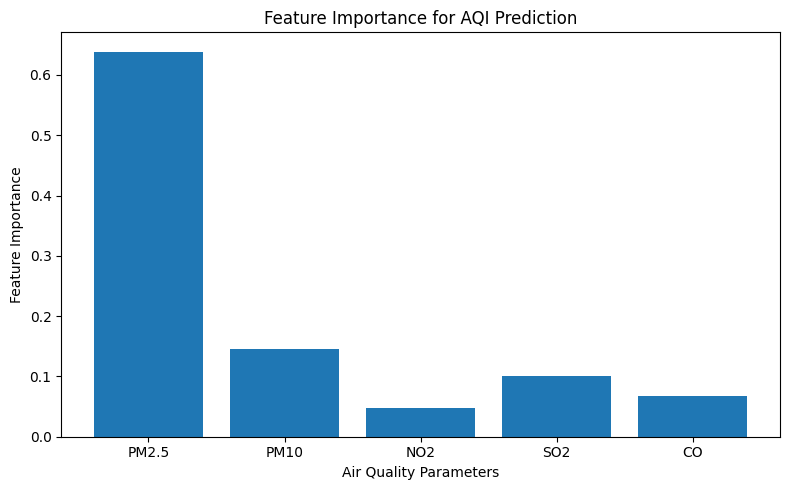

Feature Importance:
PM2.5: 0.6387
PM10: 0.1453
NO2: 0.0476
SO2: 0.1014
CO: 0.0670


In [23]:
import matplotlib.pyplot as plt

# Get feature importance
importance = model.feature_importances_

# Plot feature importance
plt.figure(figsize=(8, 5))
plt.bar(features, importance)

plt.xlabel("Air Quality Parameters")
plt.ylabel("Feature Importance")
plt.title("Feature Importance for AQI Prediction")

plt.tight_layout()
plt.show()

# Display values
print("Feature Importance:")
for feature, value in zip(features, importance):
    print(f"{feature}: {value:.4f}")

In [12]:
# Remove rows where AQI is missing
valid = y.notna()

X = X[valid]
y = y[valid]

# Fill missing predictor values with median
imputer = SimpleImputer(strategy="median")

X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=features
)

print("Missing values after handling:")
print(X.isnull().sum())

Missing values after handling:
PM2.5    0
PM10     0
NO2      0
SO2      0
CO       0
dtype: int64


In [16]:
# Re-initialize X and y from df to ensure correct indices before processing
X = df[features].copy()
y = df[target].copy()

# Remove rows where AQI is missing
valid = y.notna()

# Filter X and y based on valid AQI values, then reset indices for alignment
X = X[valid].reset_index(drop=True)
y = y[valid].reset_index(drop=True)

# Fill missing predictor values with median
imputer = SimpleImputer(strategy="median")

X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=features
)

print("Missing values after handling:")
print(X.isnull().sum())

Missing values after handling:
PM2.5    0
PM10     0
NO2      0
SO2      0
CO       0
dtype: int64


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4309, 5)
Testing data: (1078, 5)


In [18]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [19]:
y_pred = model.predict(X_test)

print("First 10 predictions:")
print(y_pred[:10])

First 10 predictions:
[ 75.89  91.36  99.74 104.21 104.55 111.9   87.34  92.42  94.48 123.46]


In [20]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Performance")
print("------------------")
print("MAE  :", round(mae, 2))
print("RMSE :", round(rmse, 2))
print("R²   :", round(r2, 3))

Model Performance
------------------
MAE  : 8.6
RMSE : 14.17
R²   : 0.613
